Tutorial: Ply tailoring using GA for a simply-supported plate under normal load
==
Date: 4 February 2026

Author: Saullo G. P. Castro

Cite this tutorial as:

Saullo G. P. Castro. (2026). General-purpose finite element solver based on Python and Cython (Version 0.7.0). Zenodo. DOI: https://doi.org/10.5281/zenodo.6573489.

TODO(author): this record version (0.7.0) differs from the current pyfe3d version (0.12.0); confirm which version to cite.


Requirements
---

This tutorial needs `numpy`, `scipy`, `matplotlib`, `pymoo` and `pyfe3d`, e.g.
`python -m pip install numpy scipy matplotlib pymoo pyfe3d`.

Importing modules
---

The thicknesses of the $0^\circ$, $\pm 45^\circ$ and $90^\circ$ plies of every element of a
composite plate are chosen from a list of discrete values with a genetic algorithm (GA) of
`pymoo` to minimise the volume of the plate, under a limit on its maximum deflection.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.core.callback import Callback
from pymoo.algorithms.soo.nonconvex.ga import GA
from pymoo.optimize import minimize
from pymoo.operators.crossover.sbx import SBX
from pymoo.operators.mutation.pm import PM
from pymoo.operators.sampling.rnd import IntegerRandomSampling
from pymoo.operators.repair.rounding import RoundingRepair
from pymoo.termination import get_termination
from scipy.sparse.linalg import spsolve
from scipy.sparse import coo_matrix
from pyfe3d.shellprop import ShellProp
from pyfe3d import Quad4, Quad4Data, Quad4Probe, INT, DOUBLE, DOF

Ply stiffness
---

Each ply is orthotropic with the in-plane reduced stiffnesses

$$Q_{11} = \frac{E_1}{1 - \nu_{12}\nu_{21}}, \quad Q_{22} = \frac{E_2}{1 - \nu_{12}\nu_{21}}, \quad
Q_{12} = \frac{\nu_{12} E_2}{1 - \nu_{12}\nu_{21}}, \quad Q_{66} = G_{12}, \quad \nu_{21} = \nu_{12}\frac{E_2}{E_1}$$

and the transverse shear stiffnesses $G_{13}$, $G_{23}$. A ply at the angle $\theta$ has the
transformed stiffnesses $\bar{Q}_{ij}(\theta)$, with $c = \cos\theta$, $s = \sin\theta$:

$$\bar{Q}_{11} = Q_{11}c^4 + 2(Q_{12} + 2Q_{66})s^2c^2 + Q_{22}s^4, \quad
\bar{Q}_{22} = Q_{11}s^4 + 2(Q_{12} + 2Q_{66})s^2c^2 + Q_{22}c^4$$

$$\bar{Q}_{12} = (Q_{11} + Q_{22} - 4Q_{66})s^2c^2 + Q_{12}(s^4 + c^4), \quad
\bar{Q}_{66} = (Q_{11} + Q_{22} - 2Q_{12} - 2Q_{66})s^2c^2 + Q_{66}(s^4 + c^4)$$

$$\bar{Q}_{44} = G_{23}c^2 + G_{13}s^2, \quad \bar{Q}_{55} = G_{13}c^2 + G_{23}s^2, \quad
\bar{Q}_{45} = (G_{13} - G_{23})cs$$

The function below returns them in a $6 \times 6$ matrix with the Voigt ordering used by the
code ($\bar{Q}_{11}, \bar{Q}_{12}, \bar{Q}_{22}$ in the first block, the transverse shear terms at
indices 3 and 4, $\bar{Q}_{66}$ at index 5); the transverse normal row and column are zero.

In [2]:
def get_Q_matrix(E1, E2, nu12, G12, G13, G23, theta_deg):
    """
    Calculate the transformed reduced stiffness matrix Q_bar for a given angle.
    """
    nu21 = nu12 * E2 / E1
    denom = 1 - nu12 * nu21
    Q11 = E1 / denom
    Q22 = E2 / denom
    Q12 = nu12 * E2 / denom
    Q66 = G12

    c = np.cos(np.radians(theta_deg))
    s = np.sin(np.radians(theta_deg))

    c2 = c**2; s2 = s**2; c4 = c**4; s4 = s**4

    Q_bar_11 = Q11*c4 + 2*(Q12 + 2*Q66)*s2*c2 + Q22*s4
    Q_bar_22 = Q11*s4 + 2*(Q12 + 2*Q66)*s2*c2 + Q22*c4
    Q_bar_12 = (Q11 + Q22 - 4*Q66)*s2*c2 + Q12*(s4 + c4)
    Q_bar_66 = (Q11 + Q22 - 2*Q12 - 2*Q66)*s2*c2 + Q66*(s4 + c4)

    Q_bar_44 = G23 * c2 + G13 * s2
    Q_bar_55 = G13 * c2 + G23 * s2
    Q_bar_45 = (G13 - G23) * c * s

    Q_bar = np.array([
        [Q_bar_11, Q_bar_12, 0, 0, 0, 0],
        [Q_bar_12, Q_bar_22, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0],
        [0, 0, 0, Q_bar_44, Q_bar_45, 0],
        [0, 0, 0, Q_bar_45, Q_bar_55, 0],
        [0, 0, 0, 0, 0, Q_bar_66]
    ])
    return Q_bar

Smeared laminate and plate model
---

A rectangular plate $a \times b$, simply supported on its four edges, carries a point load $P$
normal to its mid-plane at the centre. The design variables are three integers per element that select, from a list of allowed values,
the thickness $h_0$ of the $0^\circ$ plies, $h_{45}$ of each of the $+45^\circ$ and $-45^\circ$
plies, and $h_{90}$ of the $90^\circ$ plies. The laminate
of each element is smeared: the stacking sequence is not modelled, and the stiffnesses are

$$h = h_0 + 2h_{45} + h_{90}, \qquad
\mathbf{A} = h_0\bar{\mathbf{Q}}(0^\circ) + h_{45}\left[\bar{\mathbf{Q}}(45^\circ) + \bar{\mathbf{Q}}(-45^\circ)\right] + h_{90}\bar{\mathbf{Q}}(90^\circ), \qquad
\mathbf{D} = \frac{h^2}{12}\mathbf{A}, \qquad \mathbf{B} = \mathbf{0}$$

that is, $\mathbf{D}$ is the bending stiffness of a homogeneous plate with the averaged
stiffness $\mathbf{A}/h$. The transverse shear stiffnesses $A_{44}, A_{45}, A_{55}$ take the
shear correction factor $5/6$. These values are written directly into a `ShellProp` of each
`Quad4` element.

By symmetry only the quarter $0 \le x \le a/2$, $0 \le y \le b/2$ is modelled:

- $w = 0$ at the simply supported edges $x = 0$ and $y = 0$;
- the rotation about $y$ is zero along the symmetry line $x = a/2$, and the rotation about $x$
  is zero along $y = b/2$;
- the in-plane displacements $u$, $v$ are restrained everywhere: with $\mathbf{B} = \mathbf{0}$
  the bending problem is uncoupled from the membrane one, and this also satisfies $u = 0$ at
  $x = a/2$ and $v = 0$ at $y = b/2$;
- the centre node lies on both symmetry lines, so it carries $P/4$.

The method `_evaluate` updates the element stiffness matrices for a design `var`, solves the
static problem and returns the objective `F`, the volume of the full plate (four times that of
the quarter), and the constraint `G` on the maximum deflection (next section). The class follows
the `pymoo` `ElementwiseProblem` interface.

In [3]:
class SmearedPlateOptimization(ElementwiseProblem):
    def __init__(self, nx, ny, a, b, load_val, max_deflection, thicknesses, mat_data):
        self.nx = nx
        self.ny = ny
        self.n_elems = (self.nx - 1)*(self.ny - 1)
        self.a = a
        self.b = b
        self.load_val = load_val
        self.max_deflection = max_deflection
        self.rho = mat_data['rho']

        # ply stiffness matrices for 0, 90, +45 and -45 degrees
        E1, E2 = mat_data['E1'], mat_data['E2']
        nu12, G12 = mat_data['nu12'], mat_data['G12']
        G13, G23 = mat_data['G13'], mat_data['G23']

        num_orientations = 3

        self.Q0 = get_Q_matrix(E1, E2, nu12, G12, G13, G23, 0)
        self.Q90 = get_Q_matrix(E1, E2, nu12, G12, G13, G23, 90)
        self.Q45p = get_Q_matrix(E1, E2, nu12, G12, G13, G23, 45)
        self.Q45m = get_Q_matrix(E1, E2, nu12, G12, G13, G23, -45)
        self.Q45_sum = self.Q45p + self.Q45m

        self.thicknesses = thicknesses
        self.eid_prop = {}

        n_var = num_orientations*self.n_elems

        self._init_fe_model()

        super().__init__(n_var=n_var,
                         n_obj=1,
                         n_ieq_constr=1,
                         xl=0,
                         xu=len(thicknesses) - 1,
                         vtype=int)

    def _init_fe_model(self):
        data = Quad4Data()
        probe = Quad4Probe()

        # quarter plate, 0 <= x <= a/2, 0 <= y <= b/2
        xtmp = np.linspace(0, self.a/2, self.nx)
        ytmp = np.linspace(0, self.b/2, self.ny)
        xmesh, ymesh = np.meshgrid(xtmp, ytmp)
        ncoords = np.vstack((xmesh.T.flatten(), ymesh.T.flatten(), np.zeros_like(ymesh.T.flatten()))).T
        self.ncoords = ncoords
        ncoords_flatten = ncoords.flatten()
        self.ncoords_flatten = ncoords_flatten

        nids = 1 + np.arange(ncoords.shape[0])
        nid_pos = dict(zip(nids, np.arange(len(nids))))
        nids_mesh = nids.reshape(self.nx, self.ny)
        n1s = nids_mesh[:-1, :-1].flatten()
        n2s = nids_mesh[1:, :-1].flatten()
        n3s = nids_mesh[1:, 1:].flatten()
        n4s = nids_mesh[:-1, 1:].flatten()

        num_elements = len(n1s)

        self.KC0r = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
        self.KC0c = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
        self.KC0v = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
        self.N = DOF*self.nx*self.ny

        self.quads = []
        init_k_KC0 = 0
        eid = -1
        for n1, n2, n3, n4 in zip(n1s, n2s, n3s, n4s):
            # placeholder property, overwritten in _evaluate
            prop = ShellProp()
            eid += 1
            self.eid_prop[eid] = prop

            quad = Quad4(probe)
            quad.eid = eid
            quad.n1 = n1
            quad.n2 = n2
            quad.n3 = n3
            quad.n4 = n4
            quad.c1 = DOF*nid_pos[n1]
            quad.c2 = DOF*nid_pos[n2]
            quad.c3 = DOF*nid_pos[n3]
            quad.c4 = DOF*nid_pos[n4]
            quad.init_k_KC0 = init_k_KC0
            quad.update_rotation_matrix(ncoords_flatten)
            quad.update_probe_xe(ncoords_flatten)
            quad.update_KC0(self.KC0r, self.KC0c, self.KC0v, prop)
            self.quads.append(quad)
            init_k_KC0 += data.KC0_SPARSE_SIZE

    def _evaluate(self, var, out, *args, **kwargs):
        total_volume = 0.0

        # zeroing the values of the sparse stiffness matrix before updating them
        self.KC0v *= 0

        for i, quad in enumerate(self.quads):
            prop = self.eid_prop[quad.eid]
            h0 = self.thicknesses[var[3*i]]
            h45 = self.thicknesses[var[3*i + 1]]
            h90 = self.thicknesses[var[3*i + 2]]

            h_total = h0 + 2*h45 + h90

            # smeared stiffness
            A = (h0 * self.Q0) + (h90 * self.Q90) + (h45 * self.Q45_sum)
            D = (h_total**2 / 12.0) * A

            # membrane stiffness
            prop.A11 = A[0, 0]
            prop.A12 = A[0, 1]
            prop.A22 = A[1, 1]
            prop.A66 = A[5, 5]

            # transverse shear stiffness, with the shear correction factor 5/6
            prop.A44 = 5/6.*A[3, 3]
            prop.A45 = 5/6.*A[3, 4]
            prop.A55 = 5/6.*A[4, 4]

            # bending stiffness
            prop.D11 = D[0, 0]
            prop.D12 = D[0, 1]
            prop.D22 = D[1, 1]
            prop.D66 = D[5, 5]

            prop.h = h_total

            quad.update_probe_xe(self.ncoords_flatten)
            quad.update_KC0(self.KC0r, self.KC0c, self.KC0v, prop, update_KC0v_only=1)

            total_volume += quad.area * h_total

        KC0 = coo_matrix((self.KC0v, (self.KC0r, self.KC0c)), shape=(self.N, self.N)).tocsc()

        bk = np.zeros(self.N, dtype=bool)

        x = self.ncoords[:, 0]
        y = self.ncoords[:, 1]

        # in-plane displacements u and v restrained everywhere
        bk[0::DOF] = True
        bk[1::DOF] = True

        # simply supported edges x = 0 and y = 0
        at_edges = np.isclose(x, 0.) | np.isclose(y, 0.)
        bk[2::DOF][at_edges] = True

        # symmetry about x = a/2: rotation about y restrained
        at_sym_along_x = np.isclose(x, self.a/2)
        bk[4::DOF][at_sym_along_x] = True

        # symmetry about y = b/2: rotation about x restrained
        at_sym_along_y = np.isclose(y, self.b/2)
        bk[3::DOF][at_sym_along_y] = True

        bu = ~bk

        # point load at the centre node, one quarter of the load of the full plate
        fext = np.zeros(self.N)
        fmid = self.load_val/4
        check = np.isclose(x, self.a/2) & np.isclose(y, self.b/2)
        fext[2::DOF][check] = fmid

        KC0uu = KC0[bu, :][:, bu]

        # solving the static system
        uu = spsolve(KC0uu, fext[bu])

        u = np.zeros(self.N)
        u[bu] = uu

        # deflections in the z direction and their maximum absolute value
        self.result_w = u[2::DOF]
        w_max = np.max(np.abs(self.result_w))

        # volume of the full plate, four times that of the quarter
        out["F"] = 4*total_volume
        out["G"] = [w_max/self.max_deflection - 1]

Objective, constraint and history
---

The optimisation problem reads

$$\min_{\mathbf{k}} V(\mathbf{k}) \quad \text{subject to} \quad
g(\mathbf{k}) = \frac{w_{\max}(\mathbf{k})}{w_{\text{allow}}} - 1 \le 0$$

with $V$ the volume of the plate, $w_{\max}$ its maximum absolute deflection and $\mathbf{k}$ the
integer indices of the ply thicknesses. `pymoo` takes the objective `F` and the constraint
`G` $\le 0$ directly from `_evaluate`. The callback below stores, after each generation, the
best feasible design found so far.

In [4]:
class HistorySaver(Callback):
    def __init__(self):
        super().__init__()
        self.n_evals = []
        self.F = []  # objective history
        self.G = []  # constraint history
        self.best_X = None
        self.best_F = None
        self.best_G = None

    def notify(self, algorithm):
        # best individuals found so far
        if len(algorithm.opt) > 0:
            best_ind = algorithm.opt[0]

            self.n_evals.append(algorithm.evaluator.n_eval)
            self.F.append(best_ind.F[0])

            g_val = best_ind.G[0] if best_ind.G is not None else 0.0
            self.G.append(g_val)

            self.best_X = best_ind.X.copy()
            self.best_F = best_ind.F[0]
            self.best_G = g_val

Problem data
---

A $2 \times 1$ m plate under a central load $P = 80$ N, with the allowed deflection
$w_{\text{allow}} = 1$ mm. The quarter model has $11 \times 6$ nodes, i.e. $10 \times 5$ elements
and three variables per element. Each variable selects one of the 20 thicknesses
$0.125, 0.250, \dots, 2.5$ mm.

In [5]:
# carbon/epoxy ply properties
mat_data = {
    'E1': 140e9,
    'E2': 10e9,
    'nu12': 0.3,
    'G12': 5e9,
    'G13': 5e9,
    'G23': 5e9,
    'rho': 1600.0
}

# allowed discrete thickness values
thicknesses = 0.125*1e-3*np.arange(1, 21)

problem = SmearedPlateOptimization(
    nx=11, ny=6,
    a=2.0, b=1.0,
    load_val=80.0,
    max_deflection=0.001,
    thicknesses=thicknesses,
    mat_data=mat_data
)
print('number of elements of the quarter model:', problem.n_elems)
print('number of design variables:', problem.n_var)

number of elements of the quarter model: 50
number of design variables: 150


Optimisation with a genetic algorithm
---

The GA evolves a population of 200 designs over 100 generations, without gradients. The initial
population is sampled at random among the integer indices. Offspring come from simulated binary
crossover (SBX) and polynomial mutation (PM), both rounded back to integers. Their distribution
index $\eta$ controls the spread: a low value (e.g. 2 to 5) gives a flat, wide distribution and
offspring that can be far from their parents (exploration); a high value (e.g. 20 to 30) gives a
narrow distribution and offspring close to their parents (exploitation). The seed is fixed, so
the run is repeatable.

In [6]:
algorithm = GA(
    pop_size=200,
    sampling=IntegerRandomSampling(),
    crossover=SBX(prob=1.0, eta=2, repair=RoundingRepair()),
    mutation=PM(prob=0.1, eta=10, repair=RoundingRepair()),
    eliminate_duplicates=True
)

termination = get_termination("n_gen", 100)

history = HistorySaver()

res = minimize(problem,
               algorithm,
               termination,
               seed=7,
               verbose=True,
               save_history=False,
               callback=history)

n_gen  |  n_eval  |     cv_min    |     cv_avg    |     f_avg     |     f_min    
     1 |      200 |  0.000000E+00 |  0.8200657581 |  0.0109400000 |  0.0109400000


     2 |      400 |  0.000000E+00 |  0.4168906600 |  0.0108250000 |  0.0107100000


     3 |      600 |  0.000000E+00 |  0.2638469083 |  0.0108858333 |  0.0107100000


     4 |      800 |  0.000000E+00 |  0.1550693521 |  0.0110059375 |  0.0105650000


     5 |     1000 |  0.000000E+00 |  0.0794551013 |  0.0110521622 |  0.0103600000


     6 |     1200 |  0.000000E+00 |  0.0291233915 |  0.0109810274 |  0.0099950000


... (90 outputs left out)

    97 |    19400 |  0.000000E+00 |  0.000000E+00 |  0.0060898000 |  0.0058900000


    98 |    19600 |  0.000000E+00 |  0.000000E+00 |  0.0060715500 |  0.0058900000


    99 |    19800 |  0.000000E+00 |  0.000000E+00 |  0.0060508500 |  0.0058900000


   100 |    20000 |  0.000000E+00 |  0.000000E+00 |  0.0060298250 |  0.0058450000


Results
---

The best design is analysed once more to print its volume and maximum deflection, and the mean
thickness of each ply orientation over the elements. The convergence plot shows the volume of
the best feasible design against the number of evaluations.

evaluations: 20000
volume of the best plate: 5.8450e-03 m^3
maximum deflection: 0.9967 mm (allowed 1.0 mm)
constraint value g: -3.3454e-03
mean thicknesses [mm]: h0 = 0.6800, h45 = 0.7425, h90 = 0.7575


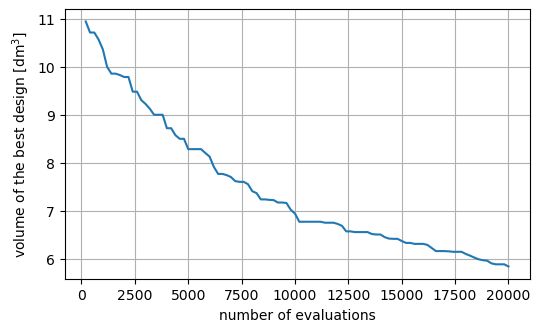

In [7]:
out_final = {}
problem._evaluate(history.best_X, out_final)
w_max = np.max(np.abs(problem.result_w))
h0_vals = thicknesses[history.best_X[0::3]]
h45_vals = thicknesses[history.best_X[1::3]]
h90_vals = thicknesses[history.best_X[2::3]]

print(f"evaluations: {history.n_evals[-1]}")
print(f"volume of the best plate: {out_final['F']:.4e} m^3")
print(f"maximum deflection: {w_max*1e3:.4f} mm (allowed {problem.max_deflection*1e3:.1f} mm)")
print(f"constraint value g: {out_final['G'][0]:.4e}")
print(f"mean thicknesses [mm]: h0 = {h0_vals.mean()*1e3:.4f}, h45 = {h45_vals.mean()*1e3:.4f}, "
      f"h90 = {h90_vals.mean()*1e3:.4f}")

plt.figure(figsize=(6, 3.5))
plt.plot(history.n_evals, np.array(history.F)*1e3)
plt.xlabel('number of evaluations')
plt.ylabel('volume of the best design [dm$^3$]')
plt.grid(True)
plt.show()

Optimised design
---

The figure shows, on the modelled quarter of the plate ($x$ from the simply supported edge to the
centre line at $a/2$), the deflection $w$ of the optimised design and the thicknesses $h_0$,
$h_{45}$ and $h_{90}$ of each element.

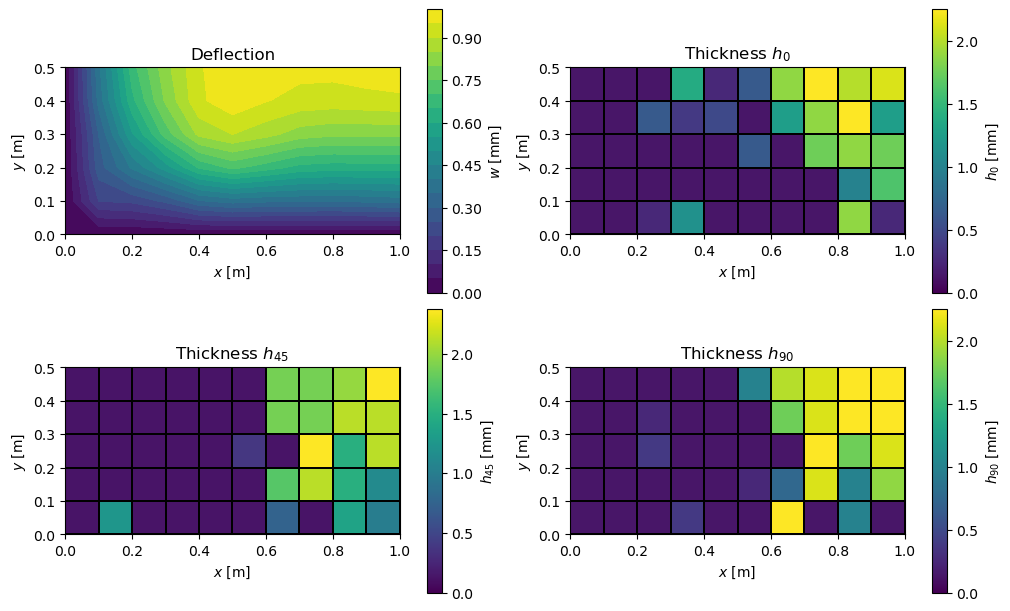

In [8]:
def plot_design(problem, h0_vals, h45_vals, h90_vals):
    nx, ny = problem.nx, problem.ny
    xg = problem.ncoords[:, 0].reshape(nx, ny)
    yg = problem.ncoords[:, 1].reshape(nx, ny)
    w = problem.result_w.reshape(nx, ny)

    fig, axes = plt.subplots(2, 2, figsize=(10, 6), constrained_layout=True)

    ax = axes[0, 0]
    cs = ax.contourf(xg, yg, w*1e3, levels=20, cmap='viridis')
    fig.colorbar(cs, ax=ax, label='$w$ [mm]')
    ax.set_title('Deflection')

    for ax, vals, name in zip([axes[0, 1], axes[1, 0], axes[1, 1]],
                              [h0_vals, h45_vals, h90_vals],
                              ['$h_0$', '$h_{45}$', '$h_{90}$']):
        # element i has the indices (ix, iy) with i = ix*(ny - 1) + iy
        vals_grid = np.asarray(vals).reshape(nx - 1, ny - 1)
        pc = ax.pcolormesh(xg, yg, vals_grid*1e3, cmap='viridis', edgecolors='k',
                           linewidth=0.3, vmin=0, vmax=np.max(vals_grid*1e3))
        fig.colorbar(pc, ax=ax, label=name + ' [mm]')
        ax.set_title('Thickness ' + name)

    for ax in axes.flatten():
        ax.set_aspect('equal')
        ax.set_xlabel('$x$ [m]')
        ax.set_ylabel('$y$ [m]')
    plt.show()


plot_design(problem, h0_vals, h45_vals, h90_vals)